```{index} single: application; seating allocation

```

```{index} single: solver; HiGHS

```

```{index} single: solver; CBC

```

```{index} single: solver; Gurobi

```

```{index} single: Pyomo; parameters

```

```{index} single: Pyomo; sets

```

```{index} network optimization

```

```{index} max flow problem

```

```{index} networkx

```

```{index} feasibility problem

```

# 4.1 Dinner seating arrangement


## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

See [Solvers used in this book](../appendix/installing-pyomo-and-solvers.ipynb) for installation, licensing and the differences between solver interfaces.


In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)
SOLVER.options["threads"] = 1

assert SOLVER.available(), f"Solver {solver} is not available."

## Problem description

Assume that we are organizing a wedding dinner and our goal is to have guests from different families mingle with each other as much as possible. One way to do this is to seat people at tables so that no more people than a given threshold $k_{\max}$ from the same family sit at the same table. How could we solve a problem like this?

First, we need the problem data. For each family $f \in F$ we need to know the number of its members $m_f$, and for each table $t \in T$ we need to know its capacity $c_t$. Using these data and the tools we have learned so far, we can formulate this problem as a LO problem.

If we are not concerned about specific individuals, but only about the number of people in a given family, then we can use variable $x_{ft}$ to determine the number of people in family $f$ who will sit at table $t$. In the problem formulation, we were not given any objective function, since our goal is to find a feasible seating arrangement. For this reason, we can set the objective function to a constant value, say $0$, and, in this way, do not differentiate between the various feasible solutions.

The mathematical formulation of this seating allocation problem is:

$$
\begin{align*}
    \min \quad & 0\\
    \text{s.t.} \quad & \sum\limits_{f} x_{ft} \leq c_t && \forall \, t \in T \\
    & \sum\limits_{t} x_{ft} = m_f && \forall \, f \in F \\
    & 0 \leq x_{ft} \leq k_{\max} && \forall \, f\in F,\ t\in T.
\end{align*}
$$

The constraints ensure that the seating capacity for each table is not exceeded, that each family is fully seated, and that the number of members of each family at each table does not exceed the threshold $k_{\max}$.


## Implementation

The problem statement will be satisfied by finding a feasible solution, if one exists. Because no specific objective has been specified, the mathematical formulation uses a constant 0 as essentially a placeholder for the objective function. Some optimization solvers, however, issue warning messages if they detect a constant objective, and others will fail to execute at all. A simple workaround is to minimize a dummy variable constrained to $[0,1]$, as in the code below.


In [2]:
import pyomo.environ as pyo
from IPython.display import display
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def seat_allocation(members, capacity, kmax, domain=pyo.NonNegativeReals):
    m = pyo.ConcreteModel("Seating arrangement")

    m.F = pyo.Set(initialize=range(len(members)))
    m.T = pyo.Set(initialize=range(len(capacity)))

    m.M = pyo.Param(m.F, initialize=members)
    m.C = pyo.Param(m.T, initialize=capacity)

    m.x = pyo.Var(m.F, m.T, bounds=(0, kmax), domain=domain)
    m.dummy = pyo.Var(bounds=(0, 1), initialize=0)

    @m.Objective(sense=pyo.minimize)
    def goal(m):
        return m.dummy

    @m.Constraint(m.T)
    def capacity(m, t):
        return pyo.quicksum(m.x[f, t] for f in m.F) <= m.C[t]

    @m.Constraint(m.F)
    def seat(m, f):
        return pyo.quicksum(m.x[f, t] for t in m.T) == m.M[f]

    return m


def get_solution(model):
    df = pd.DataFrame()
    for idx, x in model.x.items():
        f, t = idx
        df.loc[f, t] = x()
    df.index.name = "family"
    df.columns = [f"table {i}" for i in model.T]
    return df


def report(model, results, type=int, verbose=False):
    if verbose:
        print(f"Solver status: {results.solver.status}")
        print(f"Termination condition: {results.solver.termination_condition}")
    pyo.assert_optimal_termination(results)
    raw = get_solution(model)
    values = raw.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("The solver did not return finite seating values.")
    if type is int:
        if not np.allclose(values, np.rint(values), rtol=0, atol=1e-5):
            raise ValueError("The solution is fractional; use type=float to report it.")
        soln = pd.DataFrame(np.rint(values).astype(int), index=raw.index, columns=raw.columns)
    else:
        soln = raw.astype(type).round(5)
    display(soln)
    print(f"objective:       {pyo.value(model.goal)}")
    print(f"places at table: {list(soln.sum(axis=0).round(1))}")
    print(f"members seated:  {list(soln.sum(axis=1).round(1))}")

Let us now consider and solve a specific instance of this problem with six families with sizes $m = (6, 8, 2, 9, 13, 1)$, five tables with capacities $c = (8, 8, 10, 4, 9)$, and a threshold $k_{\max}=3$ for the number of members of each family that can be seated at the same table.


In [3]:
seatplan = seat_allocation(
    members=[6, 8, 2, 9, 13, 1], capacity=[8, 8, 10, 4, 9], kmax=3
)
results = SOLVER.solve(seatplan)
report(seatplan, results, type=float)

,table 0,table 1,table 2,table 3,table 4
family,,,,,
0,3.0,0.0,3.0,-0.0,0.0
1,0.0,1.0,1.0,3.0,3.0
2,0.0,2.0,0.0,0.0,0.0
3,2.0,2.0,3.0,0.0,2.0
4,3.0,3.0,3.0,1.0,3.0
5,0.0,0.0,0.0,0.0,1.0


objective:       0.0
places at table: [8.0, 8.0, 10.0, 4.0, 9.0]
members seated:  [6.0, 8.0, 2.0, 9.0, 13.0, 1.0]


With fixed integer family sizes, table capacities and a fixed integer $k_{\max}$, this is a capacitated network-flow problem. Its feasible region has integer extreme points, so an integral optimal solution exists and can be found through a basic LO solution. This property explains the integer counts above without adding integrality constraints. It relies on the fixed capacities; making $k$ a decision variable changes that structure.


## Minimize the maximum group size

Our objective was that we make members of different families mingle as much as possible. Is $k_{\max} = 3$ the lowest possible number for which a feasible table allocation exists or can we make the tables even more diverse by bringing this number down?

In order to find out, we can make $k=k_{\max}$ a decision variable and change the objective function as to minimize $k$, obtaining the following problem:

$$
\begin{align*}
    \min \quad & k \\
    \text{s.t.} \quad & \sum_{f} x_{ft} \leq c_t && \forall \, t \in T \nonumber \\
    & \sum_{t} x_{ft} = m_f && \forall \, f \in F \nonumber \\
    & 0 \leq x_{ft} \leq k  && \forall f \in F, t \in T \nonumber \\
    & k \geq 0. \nonumber
\end{align*}
$$


In [4]:
def seat_allocation_minimize_group_size(members, capacity, domain=pyo.NonNegativeReals):
    m = pyo.ConcreteModel("Seating arrangement minimizing the maximum group size")

    m.F = pyo.Set(initialize=range(len(members)))
    m.T = pyo.Set(initialize=range(len(capacity)))

    m.M = pyo.Param(m.F, initialize=members)
    m.C = pyo.Param(m.T, initialize=capacity)

    m.x = pyo.Var(m.F, m.T, domain=domain)
    m.k = pyo.Var(domain=domain)

    @m.Objective(sense=pyo.minimize)
    def goal(m):
        return m.k

    @m.Constraint(m.T)
    def capacity(m, t):
        return pyo.quicksum(m.x[f, t] for f in m.F) <= m.C[t]

    @m.Constraint(m.F)
    def seat(m, f):
        return pyo.quicksum(m.x[f, t] for t in m.T) == m.M[f]

    @m.Constraint(m.F, m.T)
    def bound(m, f, t):
        return m.x[f, t] <= m.k

    return m

We now solve the same instance as before.


In [5]:
seatplan = seat_allocation_minimize_group_size(
    members=[6, 8, 2, 9, 13, 1], capacity=[8, 8, 10, 4, 9], domain=pyo.NonNegativeReals
)
results = SOLVER.solve(seatplan)
report(seatplan, results, type=float)

,table 0,table 1,table 2,table 3,table 4
family,,,,,
0,0.8,0.4,2.2,0.0,2.6
1,2.6,2.4,2.6,0.2,0.2
2,2.0,0.0,0.0,0.0,0.0
3,0.0,2.6,2.6,1.2,2.6
4,2.6,2.6,2.6,2.6,2.6
5,0.0,0.0,0.0,0.0,1.0


objective:       2.6
places at table: [8.0, 8.0, 10.0, 4.0, 9.0]
members seated:  [6.0, 8.0, 2.0, 9.0, 13.0, 1.0]


Unfortunately, this solution is no longer integer. Mathematically, this is because the "structure" that previously ensured integer solutions at no extra cost has been lost as a result of making $k$ a decision variable. To find the solution to this problem we need to impose that the variables are integers.

Using a MILO solver such as `HiGHS` and specifying the desired domain for the variables using `domain=pyo.NonNegativeIntegers`, we can recover the original optimal value $k = 3$.


In [6]:
seatplan = seat_allocation_minimize_group_size(
    members=[6, 8, 2, 9, 13, 1],
    capacity=[8, 8, 10, 4, 9],
    domain=pyo.NonNegativeIntegers,
)
results = SOLVER.solve(seatplan)
report(seatplan, results, type=int)

,table 0,table 1,table 2,table 3,table 4
family,,,,,
0,1,2,3,0,0
1,2,1,2,1,2
2,0,0,0,0,2
3,2,2,2,0,3
4,2,3,3,3,2
5,1,0,0,0,0


objective:       3.0
places at table: [8, 8, 10, 4, 9]
members seated:  [6, 8, 2, 9, 13, 1]


## Minimize number of tables


Let us fix again to $k_{\max} = 3$ the maximum number of family members that can be seated at the same table and focus on minimizing the number of tables used. Let us introduce a binary variable $y_t$ that is equal to 1 if table $t$ is used and 0 otherwise. We can thus consider a new optimization problem in which we minimize the sum of $y_t$ over $t\in T$. The mathematical formulation of this new problem is:

$$
\begin{align*}
    \min \quad & \sum_{t\in T} y_t\\
    \text{s.t.} \quad & \sum\limits_{f} x_{ft} \leq c_t \cdot y_t && \forall \, t \in T \\
    & \sum\limits_{t} x_{ft} = m_f && \forall \, f \in F \\
    & 0 \leq x_{ft} \leq k_{\max},\quad x_{ft}\in\mathbb{Z} && \forall f\in F,\ t\in T \\
    & y_t\in\{0,1\} && \forall t\in T.
\end{align*}
$$

We can implement it in Pyomo as follows.


In [7]:
def seat_allocation_minimize_tables(
    members, capacity, kmax, domain=pyo.NonNegativeReals
):
    m = pyo.ConcreteModel("Seating arrangement minimizing the number of tables")
    m.F = pyo.Set(initialize=range(len(members)))
    m.T = pyo.Set(initialize=range(len(capacity)))
    m.M = pyo.Param(m.F, initialize=members)
    m.C = pyo.Param(m.T, initialize=capacity)
    m.x = pyo.Var(m.F, m.T, bounds=(0, kmax), domain=domain)
    m.y = pyo.Var(m.T, domain=pyo.Binary)

    @m.Objective(sense=pyo.minimize)
    def goal(m):
        return pyo.quicksum(m.y[t] for t in m.T)

    @m.Constraint(m.T)
    def capacity(m, t):
        return pyo.quicksum(m.x[f, t] for f in m.F) <= m.C[t] * m.y[t]

    @m.Constraint(m.F)
    def seat(m, f):
        return pyo.quicksum(m.x[f, t] for t in m.T) == m.M[f]

    return m

In [8]:
seatplan = seat_allocation_minimize_tables(
    members=[6, 8, 2, 9, 13, 1],
    capacity=[8, 8, 10, 4, 9],
    kmax=3,
    domain=pyo.NonNegativeIntegers,
)
results = SOLVER.solve(seatplan)
report(seatplan, results, type=int)

,table 0,table 1,table 2,table 3,table 4
family,,,,,
0,2,0,3,0,1
1,3,3,0,0,2
2,0,0,0,2,0
3,0,3,3,0,3
4,3,2,3,2,3
5,0,0,1,0,0


objective:       5.0
places at table: [8, 8, 10, 4, 9]
members seated:  [6, 8, 2, 9, 13, 1]


## Reformulation as a maximum-flow problem


We now return to the fixed-$k_{\max}$ seating problem, with the given tables available. Its network structure also allows us to use a specialized flow algorithm.

To illustrate this, we first visualize the seating problem using a graph where:

- the nodes on the left-hand side stand for the families;
- the nodes on the right-hand side stand for the tables;
- each left-to-right arrow has a number denoting the capacity of arc $(f, t)$ -- how many people of family $f$ can be assigned to table $t$.


![](seating_model_basic.png)


We can send flow from each family to the tables, respecting family sizes, table capacities and the fixed per-family limit $k_{\max}$. To test whether everybody can be seated, first allow partial seating and maximize the number assigned:

$$
\begin{align*}
    \max \quad & \sum_{t,f}x_{ft}\\
    \text{s.t.}\quad & \sum_f x_{ft}\leq c_t && \forall t\in T\\
    & \sum_t x_{ft}\leq m_f && \forall f\in F\\
    & 0\leq x_{ft}\leq k_{\max} && \forall f\in F,\ t\in T.
\end{align*}
$$

The original seating problem is feasible exactly when this maximum equals the total number of guests, $\sum_f m_f$. Otherwise, the optimal flow gives the largest number that can be seated. A continuous model suffices here because the capacities are fixed integers.

A Pyomo implementation follows. We then solve the same flow problem using a graph algorithm.


In [9]:
def seating_allocation_maximize_flow_to_tables(
    members, capacity, kmax, domain=pyo.NonNegativeReals
):
    m = pyo.ConcreteModel("Seating arrangement as network problem")
    m.F = pyo.Set(initialize=range(len(members)))
    m.T = pyo.Set(initialize=range(len(capacity)))
    m.M = pyo.Param(m.F, initialize=members)
    m.C = pyo.Param(m.T, initialize=capacity)
    m.x = pyo.Var(m.F, m.T, bounds=(0, kmax), domain=domain)

    @m.Objective(sense=pyo.maximize)
    def goal(m):
        return pyo.quicksum(m.x[f, t] for f in m.F for t in m.T)

    @m.Constraint(m.T)
    def capacity(m, t):
        return pyo.quicksum(m.x[f, t] for f in m.F) <= m.C[t]

    @m.Constraint(m.F)
    def seat(m, f):
        return pyo.quicksum(m.x[f, t] for t in m.T) <= m.M[f]

    return m


seatplan = seating_allocation_maximize_flow_to_tables(
    members=[6, 8, 2, 9, 13, 1],
    capacity=[8, 8, 10, 4, 9],
    kmax=3,
    domain=pyo.NonNegativeReals,
)
results = SOLVER.solve(seatplan)
report(seatplan, results, type=int)

,table 0,table 1,table 2,table 3,table 4
family,,,,,
0,0,1,2,0,3
1,3,2,3,0,0
2,0,0,2,0,0
3,2,3,0,1,3
4,3,1,3,3,3
5,0,1,0,0,0


objective:       39.0
places at table: [8, 8, 10, 4, 9]
members seated:  [6, 8, 2, 9, 13, 1]


By adding two more nodes to the graph above, we can formulate the problem as a slightly different flow problem where all the data is formulated as the arc capacity, see figure below. In a network like this, we can imagine a problem of sending resources from the _source node_ "door" to the _target node_ "seat", subject to the restriction that for any node that is neither the source nor the target, the incoming and outgoing flows are equal (_balance constraint_). If there exists a flow in this new graph that respects the arc capacities and the sum of outgoing flows at the source is equal to the total number of individuals, that is $\sum_{f \in F} m_f$, it means that there exists a family-to-table assignment that meets our requirements.


![](seating_flow_model.png)


Maximizing flow from `door` to `seat` gives the largest number of guests that can be seated. If it equals $\sum_f m_f$, everybody has a place. The following code explicitly selects NetworkX's [highest-label preflow-push algorithm](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.flow.preflow_push.html), so the chosen algorithm is clear when the notebook is rerun.


In [10]:
def model_as_network(members, capacity, kmax):
    # create lists of families and tables
    families = [f"f{i}" for i in range(len(members))]
    tables = [f"t{j}" for j in range(len(capacity))]

    # create a directed graph
    G = nx.DiGraph()

    # add edges
    G.add_edges_from(["door", f, {"capacity": n}] for f, n in zip(families, members))
    G.add_edges_from([(f, t) for f in families for t in tables], capacity=kmax)
    G.add_edges_from([t, "seat", {"capacity": n}] for t, n in zip(tables, capacity))

    return G


members = [6, 8, 2, 9, 13, 1]
capacity = [8, 8, 10, 4, 9]
G = model_as_network(members, capacity, kmax=3)

# we solve the maximum flow problem using the networkx function
flow_value, flow_dict = nx.maximum_flow(
    G, "door", "seat", flow_func=nx.algorithms.flow.preflow_push
)

# we parse and table the solution
families = [f"f{i}" for i in range(len(members))]
tables = [f"t{j}" for j in range(len(capacity))]
pd.DataFrame(flow_dict).loc[tables, families].astype("int")

,f0,f1,f2,f3,f4,f5
t0,2,0,0,2,3,1
t1,0,1,1,3,3,0
t2,1,3,0,3,3,0
t3,0,1,0,0,3,0
t4,3,3,1,1,1,0


The next two cells time the network-flow call and the continuous Pyomo solve on this small instance. Both models are constructed before the timed calls. Pyomo's solve call includes communicating the model to the solver and loading the solution; the NetworkX call runs the selected graph algorithm. The larger comparison below records the same timing scope.


In [11]:
%time flow_value, flow_dict = nx.maximum_flow(G, 'door', 'seat', flow_func=nx.algorithms.flow.preflow_push)


CPU times: total: 15.6 ms
Wall time: 999 μs


In [12]:
m = seating_allocation_maximize_flow_to_tables(
    members=[6, 8, 2, 9, 13, 1], capacity=[8, 8, 10, 4, 9],
    kmax=3, domain=pyo.NonNegativeReals
)
%time results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)


CPU times: total: 15.6 ms
Wall time: 10.8 ms


## A more systematic comparison between LO solvers and network algorithms

We compare HiGHS solving the continuous maximum-flow formulation with NetworkX's preflow-push algorithm, using the same instances for both. CBC and Gurobi are optional comparisons: set `RUN_OPTIONAL_SOLVERS = True` when they are installed and appropriately licensed. Unavailable optional solvers are reported and omitted from the plot.

Each method receives a fresh model or graph. We record construction time separately from solve-call wall time, request one thread per LO solver, and make one measurement per method and instance. Feasibility and agreement of the resulting flow values are checked outside the timers. The environment table records the machine and package versions for this run; background load is not controlled. The timings illustrate these implementations and interfaces on that machine.


In [13]:
from time import perf_counter as pc
from importlib.metadata import version
import os
import platform

# Record the environment for this run before measuring the solve calls.
cpu_name = platform.processor() or "not reported"
if sys.platform == "win32":
    import winreg
    try:
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                           r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            cpu_name = winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    except OSError:
        pass
elif os.path.isfile("/proc/cpuinfo"):
    with open("/proc/cpuinfo") as cpu_file:
        cpu_name = next((line.split(":", 1)[1].strip() for line in cpu_file
                         if line.startswith("model name")), cpu_name)
try:
    import psutil
    physical_cores = psutil.cpu_count(logical=False)
    ram_gib = round(psutil.virtual_memory().total / 2**30, 2)
except ImportError:
    physical_cores, ram_gib = "not reported", "not reported"
benchmark_environment = {
    "CPU": cpu_name, "physical cores": physical_cores,
    "logical processors": os.cpu_count(), "RAM (GiB)": ram_gib,
    "OS": platform.platform(), "Python": platform.python_version(),
    "Pyomo": version("pyomo"), "HiGHS": version("highspy"),
    "NetworkX": nx.__version__, "NumPy": np.__version__,
    "LP solver threads": 1, "random seed": 2023, "repetitions per point": 1,
    "timing": "wall time; construction and solve calls recorded separately",
    "conditions": "fresh models; no requested warm start; background load uncontrolled",
}
display(pd.Series(benchmark_environment, name="This run").to_frame())


def benchmark_solvers(include_optional=False):
    solvers = {"HiGHS LP": SOLVER}
    unavailable = []
    if include_optional:
        for label, interface in [("CBC LP", "cbc"), ("Gurobi LP", "gurobi_direct")]:
            try:
                candidate = pyo.SolverFactory(interface)
                if not candidate.available():
                    raise RuntimeError("Solver is unavailable")
                candidate.options["Threads" if interface == "gurobi_direct" else "threads"] = 1
                solvers[label] = candidate
            except Exception as exc:
                unavailable.append({"method": label, "status": "unavailable",
                                    "reason": type(exc).__name__})
    return solvers, unavailable


RUN_OPTIONAL_SOLVERS = False  # CBC/Gurobi require a separate local installation.
solvers, unavailable_solvers = benchmark_solvers(RUN_OPTIONAL_SOLVERS)
np.random.seed(2023)
kmax = 3
nmax = 500
mmax = 2 * nmax
sizes = list(zip(range(10, nmax, 10), range(20, mmax, 20)))
benchmark_records = []
failed_optional_solvers = set()

for n, m in sizes:
    members = np.random.randint(1, 10, n)
    capacity = np.random.randint(3, 8, m)
    case_records = []
    for name, lp_solver in solvers.items():
        row = {"method": name, "families": n, "tables": m,
               "build_seconds": np.nan, "solve_seconds": np.nan, "flow": np.nan}
        if name in failed_optional_solvers:
            case_records.append(dict(row, status="skipped after failure"))
            continue
        start = pc()
        model = seating_allocation_maximize_flow_to_tables(
            members, capacity, kmax, domain=pyo.NonNegativeReals
        )
        row["build_seconds"] = pc() - start
        try:
            start = pc()
            results = lp_solver.solve(model)
            row["solve_seconds"] = pc() - start
            pyo.assert_optimal_termination(results)
        except Exception as exc:
            if name == "HiGHS LP":
                raise
            failed_optional_solvers.add(name)
            case_records.append(dict(row, status="solver failed", reason=type(exc).__name__))
            continue
        values = np.fromiter((var.value for var in model.x.values()), dtype=float).reshape(n, m)
        assert np.isfinite(values).all()
        assert values.min() >= -1e-6 and values.max() <= kmax + 1e-6
        assert (values.sum(axis=1) <= members + 1e-6).all()
        assert (values.sum(axis=0) <= capacity + 1e-6).all()
        case_records.append(dict(row, status="optimal", flow=float(values.sum())))

    start = pc()
    G_benchmark = model_as_network(members, capacity, kmax)
    graph_seconds = pc() - start
    start = pc()
    flow_value, flow_dict = nx.maximum_flow(
        G_benchmark, "door", "seat", flow_func=nx.algorithms.flow.preflow_push
    )
    flow_seconds = pc() - start
    for row in case_records:
        if row["status"] == "optimal":
            assert np.isclose(row["flow"], flow_value, rtol=0, atol=1e-5)
    case_records.append({"method": "NetworkX preflow-push", "families": n, "tables": m,
                         "build_seconds": graph_seconds, "solve_seconds": flow_seconds,
                         "flow": float(flow_value), "status": "optimal"})
    benchmark_records.extend(case_records)

benchmark_records = pd.DataFrame(benchmark_records)
display(benchmark_records.groupby(["method", "status"]).size().rename("runs").to_frame())
if unavailable_solvers:
    display(pd.DataFrame(unavailable_solvers))


,This run
CPU,11th Gen Intel(R) Core(TM) i7-1185G7 @ 3.00GHz
physical cores,4
logical processors,8
RAM (GiB),63.73
OS,Windows-11-10.0.26300-SP0
Python,3.12.14
Pyomo,6.10.1
HiGHS,1.15.1
NetworkX,3.6.1
NumPy,2.3.5


,,runs
method,status,
HiGHS LP,optimal,49
NetworkX preflow-push,optimal,49


The following figure plots the solve-call times from this run. It includes only successful comparisons and uses the actual method names recorded above. Model and graph construction times remain available in `benchmark_records`; they are not included in these curves. The ordering can vary with instance size, solver interface and machine.


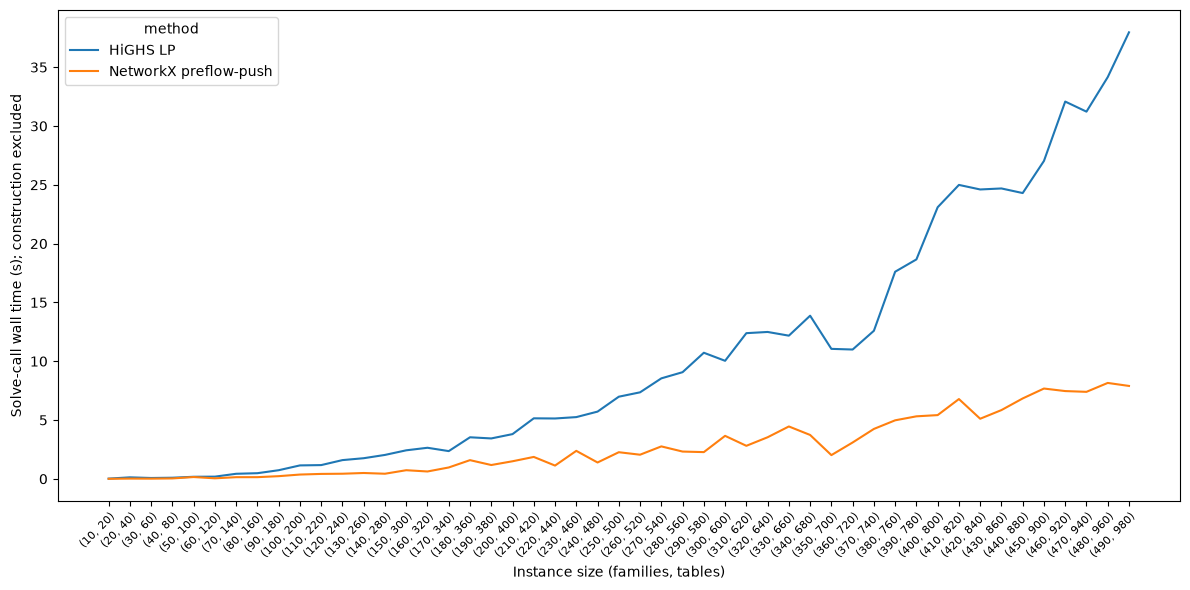

In [14]:
successful_runs = benchmark_records.loc[benchmark_records["status"] == "optimal"]
df = successful_runs.pivot(index="method", columns=["families", "tables"], values="solve_seconds")
df = df.reindex(columns=pd.MultiIndex.from_tuples(sizes))
ax = df.transpose().plot(figsize=(12, 6))
ax.set_ylabel("Solve-call wall time (s); construction excluded")
ax.set_xticks(range(len(df.columns)))
ax.set_xticklabels(df.columns, rotation=45, ha="right", fontsize=8, rotation_mode="anchor")
ax.set_xlabel("Instance size (families, tables)")
plt.tight_layout()
plt.show()
